# Sales Trend Analysis
InternCircle Project 03

**Business question** Which months and categories earn most, which customers contribute most, and what actions should a manager test?

**Data** Reproducible simulated orders, seed 73, calendar year 2025. Each row represents one completed order. Amounts are illustrative USD gross sales. The generator deliberately includes Q4 seasonality, unequal customer weights and category price differences.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
sys.path.insert(0, str(root / 'src'))
from analyze import generate_orders, prepare, analyze, main
from IPython.display import display, Image
raw = generate_orders()
display(raw.head())
print('Shape:', raw.shape)
print('Missing:', raw.isna().sum().sum(), '| Duplicate rows:', raw.duplicated().sum())
print(raw.dtypes)

Shape: (2400, 5)
Missing: 0 | Duplicate rows: 0
order_id                int64
order_date     datetime64[us]
customer_id             int64
category                  str
amount                float64
dtype: object


,order_id,order_date,customer_id,category,amount
0,174,2025-01-01,221,Books,18.40
1,250,2025-01-01,254,Books,44.24
2,769,2025-01-01,207,Home,178.20
3,1124,2025-01-01,253,Home,111.10
4,1400,2025-01-01,258,Electronics,297.96


## Date features and validation
Extract month, weekday and quarter after parsing the order date. Verify one unique identifier per order and positive amounts.

In [2]:
df = prepare(raw)
display(df[['order_date','month','weekday','quarter']].head())
monthly, categories, pivot, spend = analyze(df)

,order_date,month,weekday,quarter
0,2025-01-01,2025-01,Wednesday,Q1
1,2025-01-01,2025-01,Wednesday,Q1
2,2025-01-01,2025-01,Wednesday,Q1
3,2025-01-01,2025-01,Wednesday,Q1
4,2025-01-01,2025-01,Wednesday,Q1


## Monthly trends
Month over month growth compares each month's revenue with the preceding month. The first month has no prior observation.

In [3]:
display(monthly.round(2))
print('Best month:', monthly.revenue.idxmax())
print('Lowest month:', monthly.revenue.idxmin())

Best month: 2025-12
Lowest month: 2025-02


,revenue,orders,growth_pct,average_order_value
month,,,,
2025-01,22426.63,182,NaN,123.22
2025-02,17731.01,152,-20.94,116.65
2025-03,23200.39,187,30.85,124.07
2025-04,23458.44,194,1.11,120.92
2025-05,21085.78,166,-10.11,127.02
2025-06,21338.93,164,1.20,130.12
2025-07,25076.92,173,17.52,144.95
2025-08,23812.90,206,-5.04,115.60
2025-09,20706.05,165,-13.05,125.49


## Category comparison and pivot table
Compare total revenue, mean order value and order count. A month by category pivot reveals the contributions to each month's total.

In [4]:
display(categories.round(2))
display(pivot.round(2))

,revenue,average_order_value,orders,revenue_share_pct
category,,,,
Electronics,141370.44,212.27,666,46.84
Fashion,75792.57,90.12,841,25.11
Home,72439.54,130.76,554,24.00
Books,12221.48,36.05,339,4.05


category,Books,Electronics,Fashion,Home
month,,,,
2025-01,844.70,11330.75,5288.61,4962.57
2025-02,814.20,7342.29,4067.92,5506.60
2025-03,1060.08,10207.08,6663.31,5269.92
2025-04,797.25,11463.34,6243.20,4954.65
2025-05,1149.20,9191.46,6097.66,4647.46
2025-06,782.66,10107.63,4968.63,5480.01
2025-07,844.84,15234.07,4645.36,4352.65
2025-08,1404.21,9042.97,7476.52,5889.20
2025-09,725.64,9150.47,5228.62,5601.32


## Customer concentration
Rank observed purchasing customers by spend. Round 10% of the customer count up to a whole customer and report the resulting actual fraction.

In [5]:
import math
k = math.ceil(len(spend) * .10)
share = spend.head(k).spend.sum() / spend.spend.sum() * 100
print(f'Top {k} of {len(spend)} customers ({k / len(spend):.1%}) contribute {share:.1f}% of revenue')
display(spend.head(10).round(2))

Top 29 of 281 customers (10.3%) contribute 36.8% of revenue


,customer_id,spend,orders,cumulative_revenue_pct,customer_pct
0,221,9835.25,82,3.26,0.36
1,286,6181.47,51,5.31,0.71
2,289,4854.38,29,6.91,1.07
3,128,4729.90,39,8.48,1.42
4,89,4724.75,34,10.05,1.78
5,181,4628.58,40,11.58,2.14
6,254,4180.24,29,12.97,2.49
7,17,3969.70,20,14.28,2.85
8,164,3968.19,31,15.60,3.20
9,82,3960.71,26,16.91,3.56


## Saved charts and business recommendations
Run the complete script to export the data, summaries, charts and PDF. The README and business brief provide three specific actions using the measured results.

Revenue totals USD 301,824.03 across 2,400 orders and 281 purchasing customers.
The best month is 2025-12 at USD 37,248.74. The lowest is 2025-02 at USD 17,731.01.
Electronics contributes 46.8% of revenue with an average order value of USD 212.27.
The top 29 of 281 customers (10.3%) contribute 36.8% of revenue. The top 20% rounded up contribute 55.8%.
          revenue  orders  growth_pct  average_order_value
month                                                     
2025-01  22426.63     182         NaN               123.22
2025-02  17731.01     152      -20.94               116.65
2025-03  23200.39     187       30.85               124.07
2025-04  23458.44     194        1.11               120.92
2025-05  21085.78     166      -10.11               127.02
2025-06  21338.93     164        1.20               130.12
2025-07  25076.92     173       17.52               144.95
2025-08  23812.90     206       -5.04               115.60
2025-09  20706.05     165      -13.05               125.

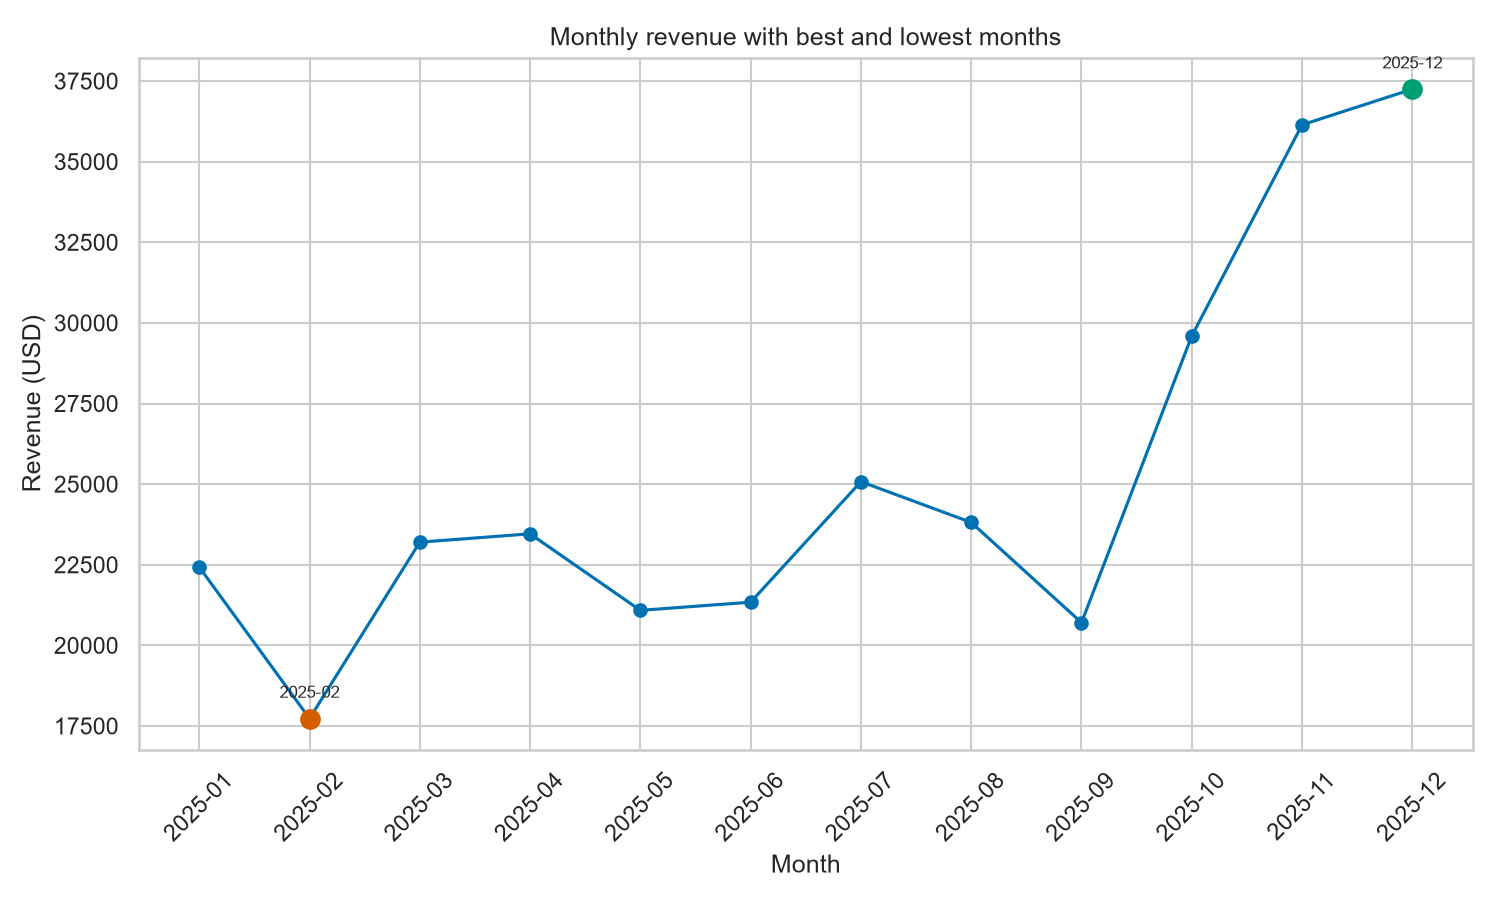

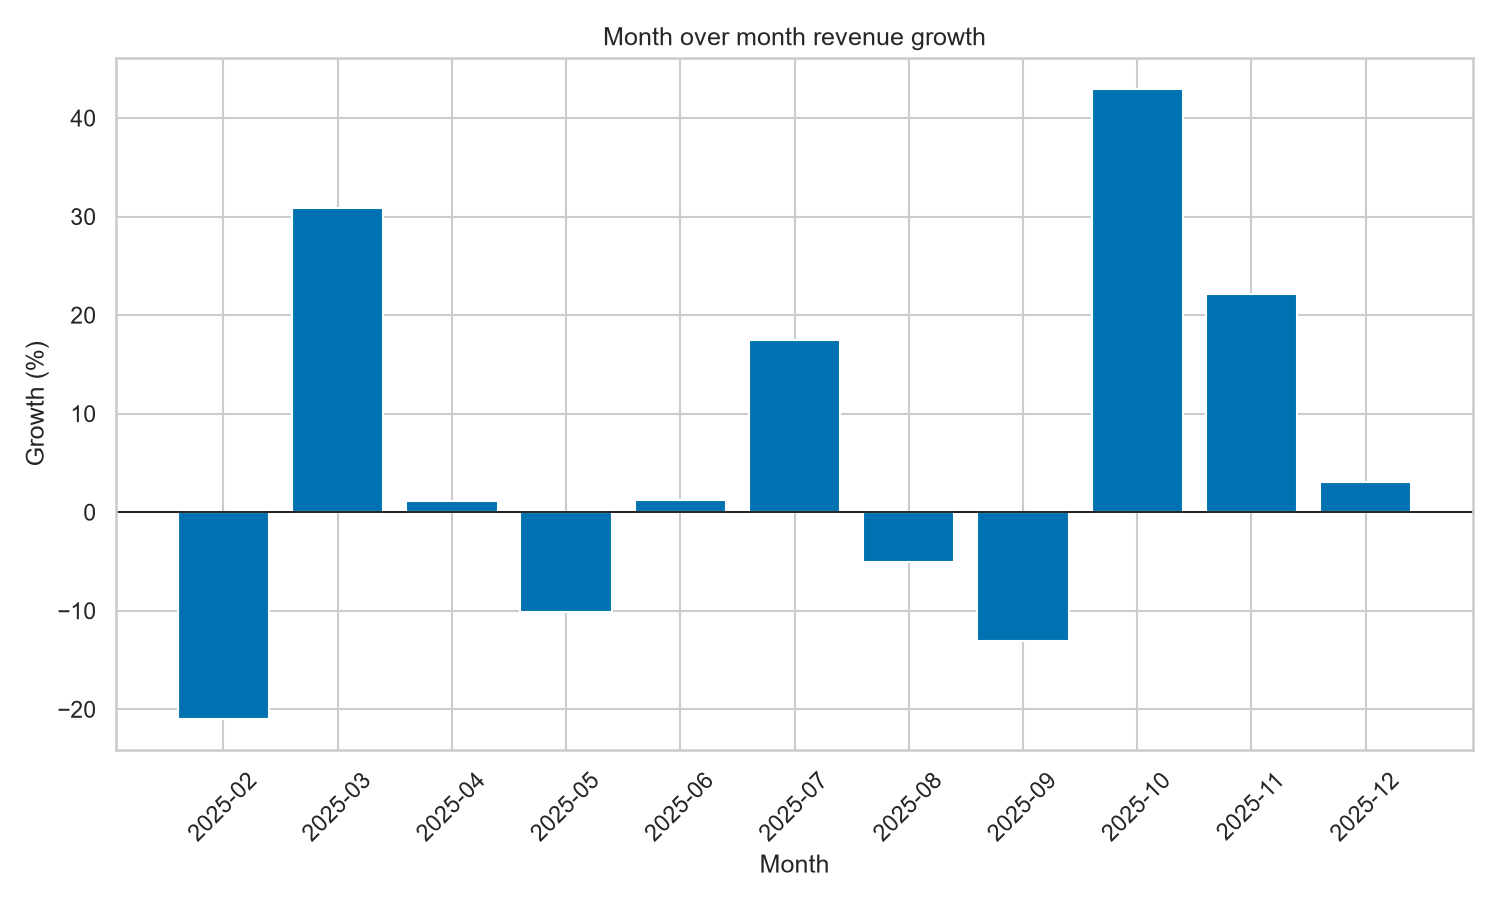

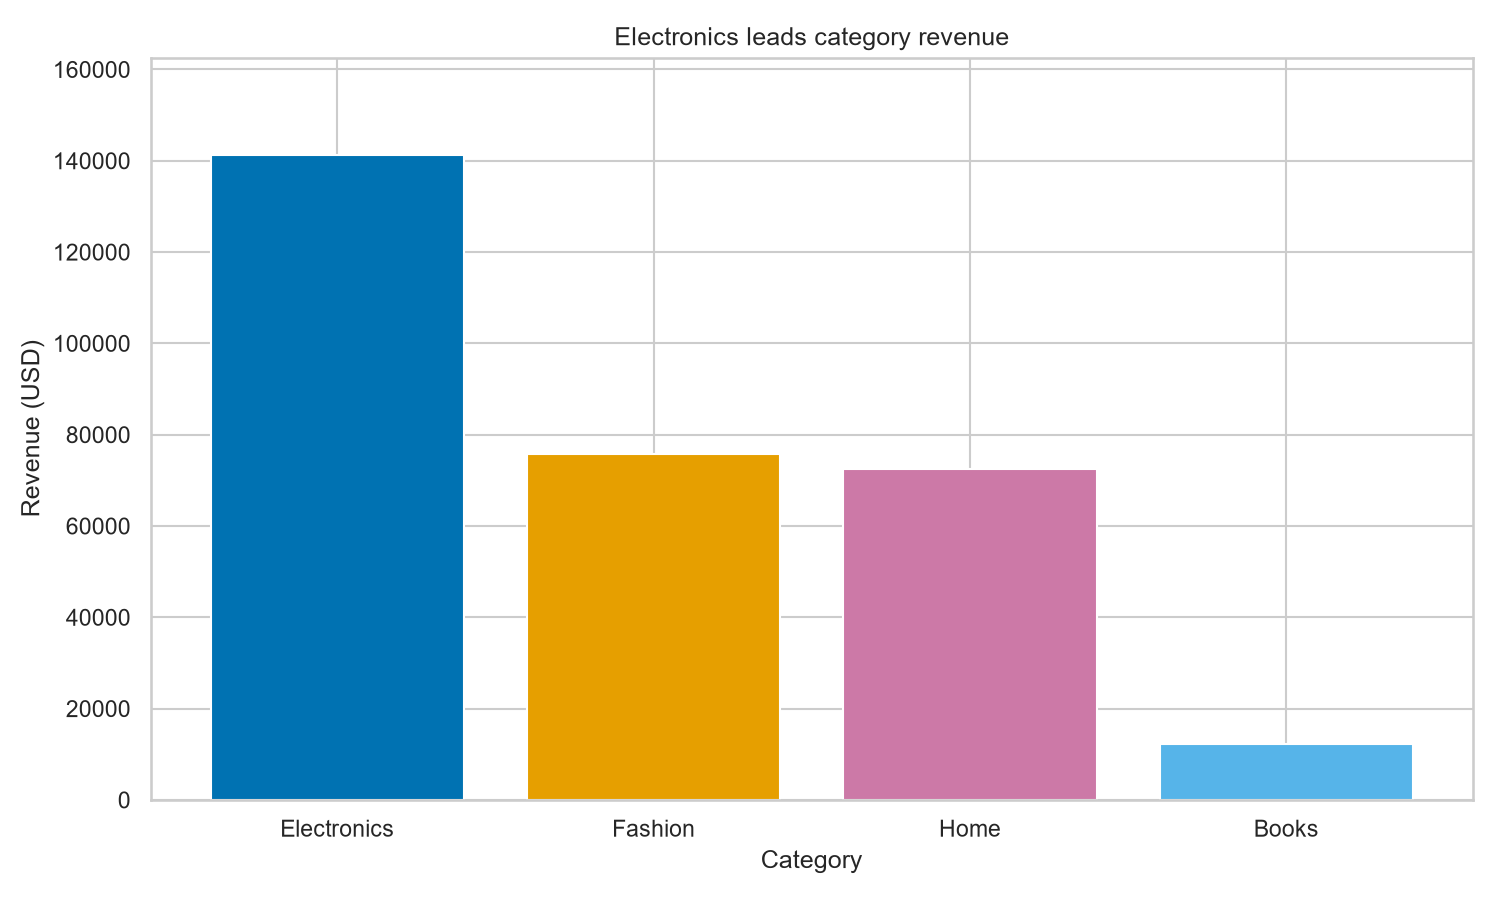

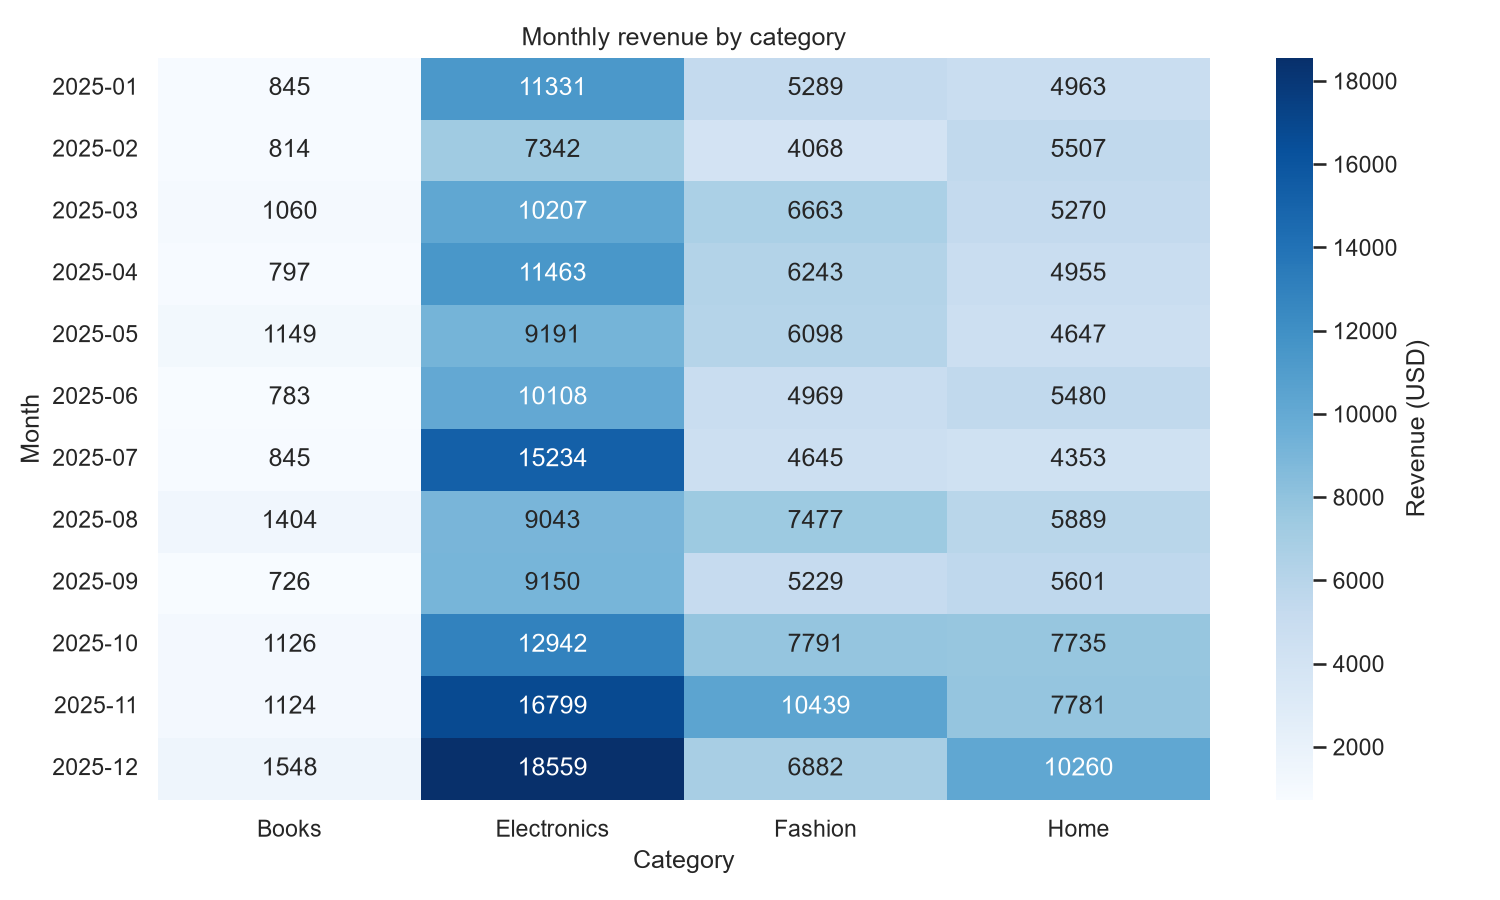

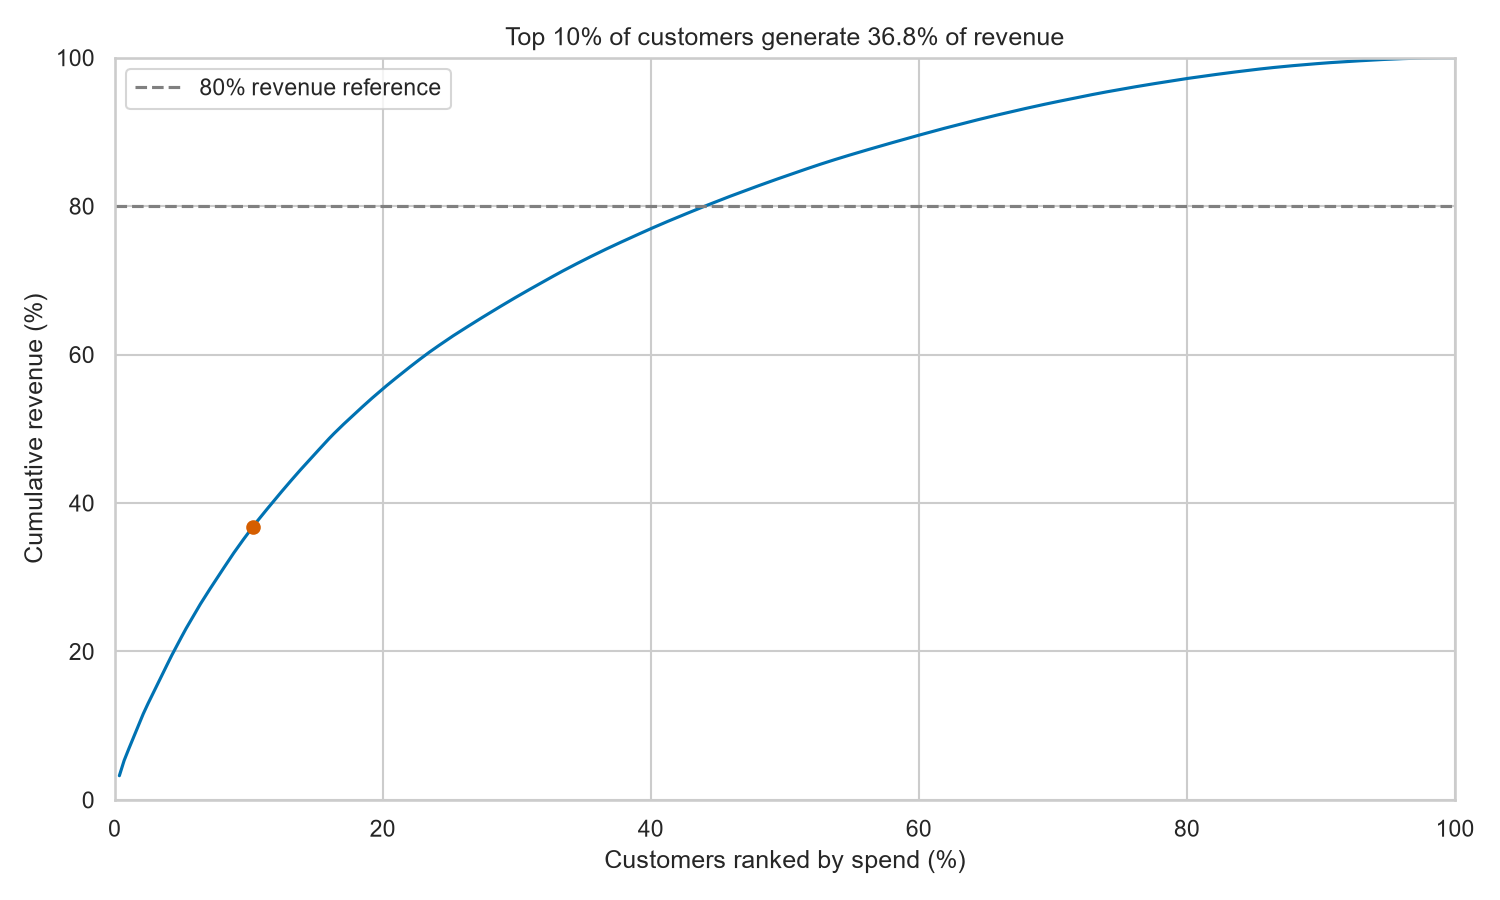

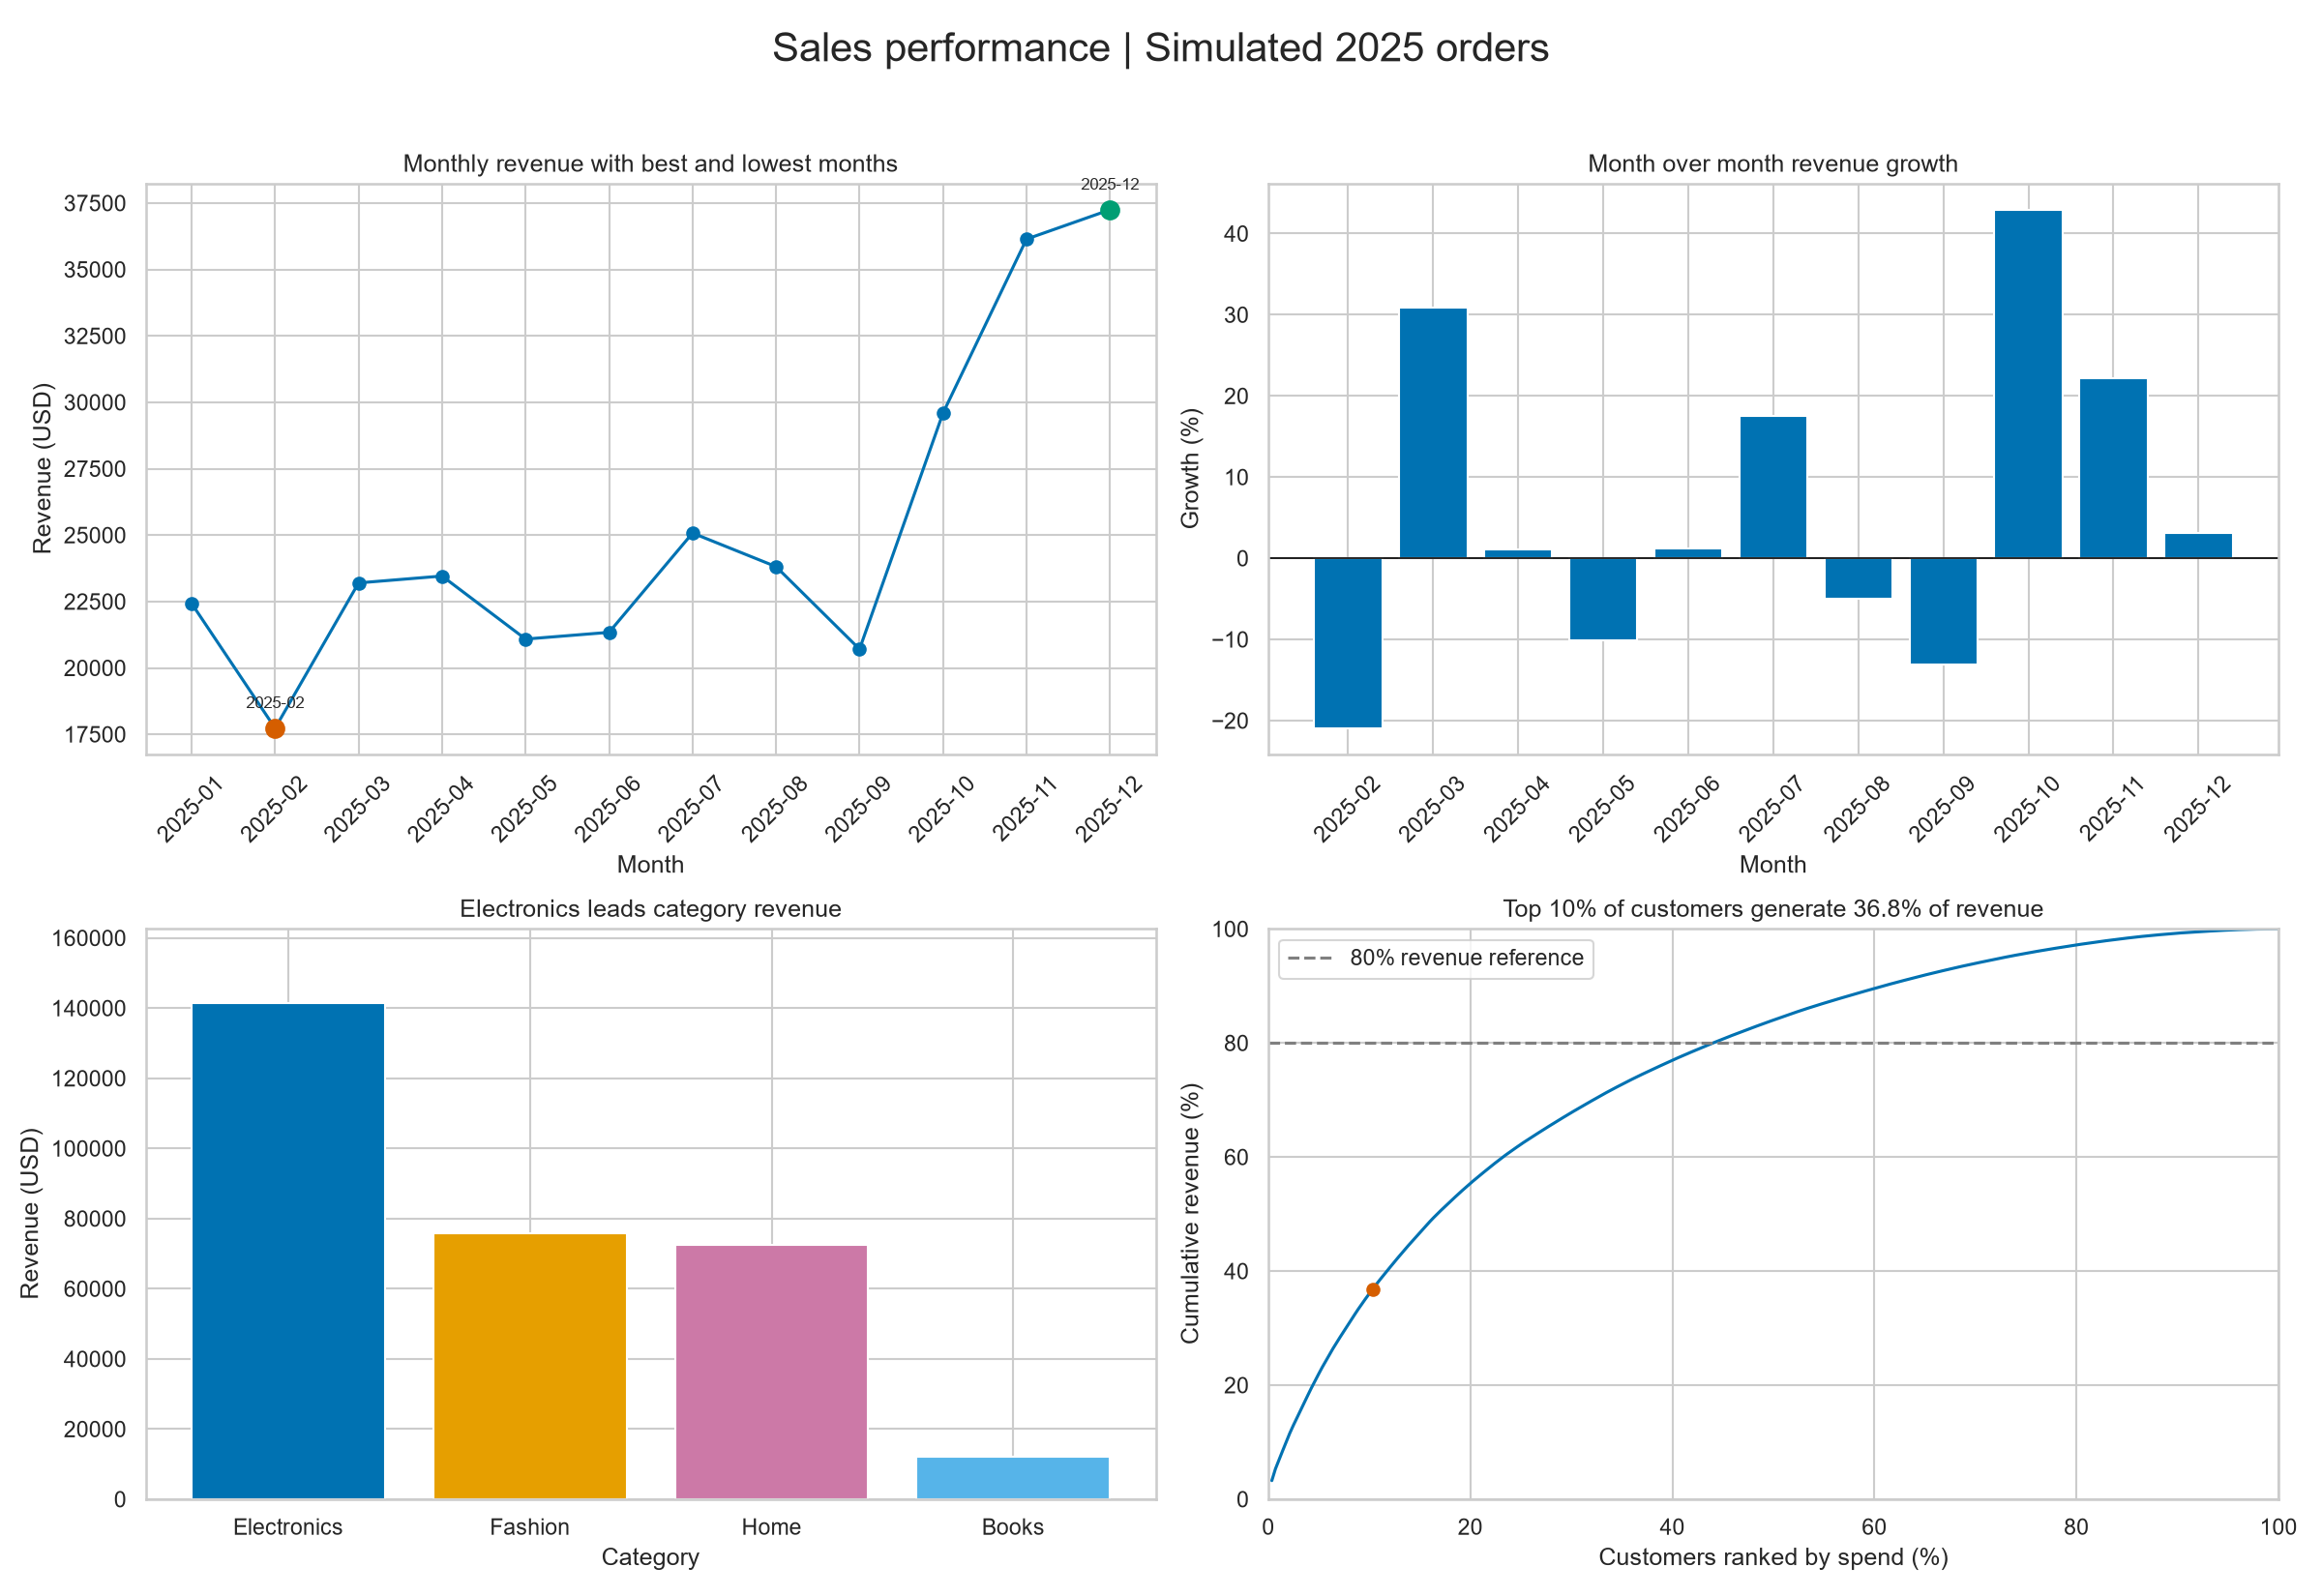

In [6]:
main()
for name in ['monthly_revenue','monthly_growth','category_revenue','category_heatmap','customer_pareto','dashboard']:
    print(name.replace('_',' ').title())
    display(Image(filename=str(root / 'visualizations' / (name + '.png')), width=850))

## Limitations and next steps
The simulated patterns reflect generator assumptions. Revenue excludes returns, costs, tax and discounts. Validate patterns using real business data and measure recommendation outcomes with controlled pilots. The dataset supports the guide's sales trend analysis, without a defined churn outcome.